# Phase 0 — Scientific Scope and Source Registry

**Thermoresponsive Hydrogel Data Curation and Workflow Engineering**

**Status:** Executable source-registration and scientific-scope foundation. Numerical spectroscopy, rheology, image measurement, and physical-sample linkage belong to later phases.

**Source study:** [Nemati Mahand *et al.* (2026), *Biomacromolecules*](https://doi.org/10.1021/acs.biomac.6c01032)  
**Experimental deposit:** [Zenodo record 21902628](https://zenodo.org/records/21902628)

## Scientific and technical aims

This phase establishes a traceable starting point for scientific data integration. Experimental archive names, file checksums, a structured account of the three polymer systems, technique requirements and preliminary quality-control rules are recorded in reproducible machine-readable outputs.

**Scientific concept:** Polymer architecture, batch, formulation, treatment and measurement conditions influence thermogelation and cannot be treated as interchangeable descriptors.  
**Data-science connection:** Each descriptor needs a defined data type, origin, meaning and quality rule before experimental data can be compared.  
**Technical approach:** Python reads the original ZIP archives without altering their contents, saves CSV and JSON registers, generates figures and writes an HTML report.

> **Evidence boundary:** Data reported in the research article are attributed as *source-reported*. File sizes, entry counts and checksums are independently calculated from the supplied ZIP archives. These results are not newly measured polymer properties. No unpublished physical-sample identifiers are inferred.

## 1. Execution environment and reproducible source configuration

**Scientific workflow engineering.** The software environment is part of the reproducible scientific record. A compiled package incompatibility, such as NumPy from a Windows per-user directory combined with pandas from Anaconda, can stop all polymer-data processing before source validation begins.

**Dedicated kernel.** Use the named `Python (Thermogel Phase 0)` kernel, created by `INSTALL_THERMOGEL_KERNEL.bat` in the project root. The installer uses an isolated conda environment and does not change the Anaconda base environment. A kernel selection box showing only `Python 3 (ipykernel)` indicates that the separate scientific environment has not yet been registered. The installer must be run before that kernel can be selected.

**Compatibility check.** The following code does not reject compatible scientific libraries that may already have been imported by JupyterLab extensions. It excludes the unrelated user-site package directory for a conda interpreter, and identifies cases in which an incompatible compiled package has already been loaded; those cases require a clean dedicated kernel rather than swapping packages inside a running Python process.

**Source location and portability.** The notebook automatically identifies the project folder and searches several nearby locations for the 13 original Zenodo ZIP archives. The preferred, portable structure stores the unmodified archives under `data/raw/zenodo_21902628/` within the project folder. A source folder outside the project may be discovered for local analysis, but should be moved into the standard location for a self-contained archive. `requirements.txt` is **not** required merely to recognise the project directory. If source ZIPs are missing, the notebook reports which filenames are absent and shows the expected folder; no experimental results are fabricated.

**Science–data connection.** The scientific registry preserves polymer architecture, experimental treatments, analytical-method requirements and source provenance. Experimental measurements and sample-specific linkages remain outside Phase 0.

In [3]:
# ---------------------------------------------------------------------------
# Phase 0: isolate Anaconda's scientific packages from an incompatible
# per-user NumPy installation before importing pandas or Matplotlib.
# The procedure changes only this running notebook process (sys.path).
# No packages are installed, removed or downgraded automatically.
# ---------------------------------------------------------------------------
import os
import site
import sys
import importlib
from pathlib import Path
from collections import Counter
import hashlib
import html
import json
import platform
import zipfile
import importlib.metadata as metadata


def _is_conda_interpreter():
    """Identify a conda interpreter without relying on a particular drive."""
    prefix = str(sys.prefix).casefold()
    return (Path(sys.prefix, 'conda-meta').is_dir()
            or 'anaconda' in prefix or 'miniconda' in prefix
            or bool(os.environ.get('CONDA_PREFIX')))


def _normalise_site_path(path):
    """Compare user-site paths consistently across Windows and POSIX."""
    return os.path.normcase(os.path.abspath(str(path))).casefold()



def _isolate_conda_from_user_site():
    """Exclude unrelated per-user packages without rejecting valid pre-imports.

    IPython/Jupyter extensions may legitimately preload NumPy and Matplotlib.
    The former guard rejected those safe preloads. Loaded modules are now
    inspected: if a scientific package was actually loaded from the external
    Windows per-user site, the notebook requests the dedicated kernel,
    because compiled modules cannot safely be swapped in a running process.
    """
    if not _is_conda_interpreter():
        return 'Non-conda interpreter: package imports use the selected kernel.'
    user_site = site.getusersitepackages()
    if not user_site:
        return 'Conda environment: no external per-user site found.'
    sites = user_site if isinstance(user_site, (list, tuple)) else [user_site]
    blocked = {_normalise_site_path(p) for p in sites}
    # Detect already-imported foreign packages BEFORE changing sys.path.
    preloaded = []
    for package in ('numpy', 'pandas', 'matplotlib'):
        module = sys.modules.get(package)
        origin = getattr(module, '__file__', None) if module is not None else None
        if origin:
            absolute_origin = _normalise_site_path(origin)
            if any(absolute_origin.startswith(base + os.sep) for base in blocked):
                raise RuntimeError(
                    f'{package} was already loaded from the incompatible user-site '
                    f'location: {origin}. A running kernel cannot safely unload '
                    'compiled Python packages. Create and select the dedicated '
                    'Python (Thermogel Phase 0) kernel using '
                    'INSTALL_THERMOGEL_KERNEL.bat from Anaconda Prompt, then '
                    'use Kernel > Restart Kernel and Run All Cells.'
                )
            preloaded.append(package)
    original_count = len(sys.path)
    sys.path[:] = [path for path in sys.path if _normalise_site_path(path) not in blocked]
    site.ENABLE_USER_SITE = False
    importlib.invalidate_caches()
    removed = original_count - len(sys.path)
    return (
        f'Conda environment: removed {removed} user-site search paths; '
        f'preloaded compatible packages: {", ".join(preloaded) or "none"}. '
        'Dedicated Python (Thermogel Phase 0) kernel is recommended.'
    )


_environment_note = _isolate_conda_from_user_site()
print('Environment check:', _environment_note)

try:
    import pandas as pd
    import numpy as np
    import matplotlib
    import matplotlib.pyplot as plt
except (ImportError, AttributeError, ValueError) as original_error:
    raise RuntimeError(
        'The active Jupyter kernel has incompatible scientific Python '
        'dependencies. The uploaded error showed NumPy 2.0.2 loaded from '
        'Windows user-site while pandas was imported from Anaconda. '
        'A clean environment is recommended: follow the repository file '
        'docs/PHASE0_ENVIRONMENT_FIX.md, create the environment from '
        'environment.yml, and select Python (Thermogel Phase 0) in Jupyter. '
        'Restart Kernel, then Run All. Original import error: '
        + str(original_error)
    ) from original_error

from IPython.display import display, HTML

# ---------------------------------------------------------------------------
# Portable project and experimental-archive discovery.
# A Jupyter kernel starts in the notebook's working directory, which may be
# different from the directory used by the original project developer.
# The previous version incorrectly required both requirements.txt and
# notebooks/ in one specific directory; this could reject valid installations.
# ---------------------------------------------------------------------------
EXPECTED_ARCHIVE_NAMES = ('Figure 2b,c,d-SEC.zip', 'Figure S16-SEC.zip', 'Figure S2,3,4,11-1H NMR.zip', 'Figure S5,6,7-FTIR.zip', 'Figure3,4,5, and S8-Rheology data.zip', 'Figure S1 and 2b-Solgel transitions.zip', 'Figure S9,10, and 6.zip', 'Figure S21-Printing.zip', 'Figure S 12,13,14-Bacterial gwroth test.zip', 'Figure S15-Bacterial growth after 3time Filtration.zip', 'Figure S17-Autoclave followed by filtration.zip', 'Figure S18.zip', 'Figure S19,20,22-Sterilization of hydrogels by UV.zip')

# Advanced configuration: set these ONLY if automatic discovery is insufficient.
# Both values remain None for ordinary use; neither refers to a private PC.
PROJECT_ROOT_OVERRIDE = None  # Example: Path(r'D:\projects\thermogel-data')
ARCHIVE_DIR_OVERRIDE = None   # Example: Path(r'D:\materials\original_zips')

cwd = Path.cwd().resolve()

def _candidate_project_root():
    """Find the repository even when Jupyter starts in data/raw/zenodo_21902628.

    A repository can contain its notebook at the root (as in this project),
    so neither a notebooks/ folder nor requirements.txt is mandatory.
    """
    if PROJECT_ROOT_OVERRIDE is not None:
        root = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f'PROJECT_ROOT_OVERRIDE does not exist: {root}')
        return root

    # Check the working directory and its ancestors, including when Jupyter
    # is displaying files inside data/raw/zenodo_21902628.
    for folder in (cwd, *cwd.parents):
        if folder.name.casefold() == 'thermoresponsive-hydrogel-data-curation':
            return folder
        if (folder / 'data' / 'raw' / 'zenodo_21902628').is_dir():
            return folder
        if ((folder / 'data' / 'raw').is_dir() and
            ((folder / '00_scope_and_source_registry.ipynb').is_file() or
             (folder / 'notebooks').is_dir())):
            return folder

    # Windows Anaconda may start Jupyter in the user home directory rather
    # than in the repo. Try standard user Documents locations; the user name,
    # drive letter and home path are never hard-coded.
    home = Path.home()
    for candidate in (
        home / 'Documents' / 'thermoresponsive-hydrogel-data-curation',
        home / 'OneDrive' / 'Documents' / 'thermoresponsive-hydrogel-data-curation',
    ):
        if (candidate / 'data' / 'raw' / 'zenodo_21902628').is_dir():
            return candidate.resolve()

    if cwd.name.casefold() == 'notebooks':
        return cwd.parent
    # A notebook copied to a standalone directory can still work if its
    # original ZIPs are placed nearby; no output files are invented.
    return cwd

PROJECT_ROOT = _candidate_project_root()

def _archive_candidates():
    if ARCHIVE_DIR_OVERRIDE is not None:
        candidate = Path(ARCHIVE_DIR_OVERRIDE).expanduser().resolve()
        if not candidate.is_dir():
            raise FileNotFoundError(f'ARCHIVE_DIR_OVERRIDE does not exist: {candidate}')
        return [candidate]
    # Preferred locations come first, followed by reasonable nearby folders.
    bases = [PROJECT_ROOT, cwd]
    for base in (PROJECT_ROOT, cwd):
        bases.extend(list(base.parents)[:3])
    unique_bases = list(dict.fromkeys(bases))
    candidates = []
    for base in unique_bases:
        candidates.extend((
            base / 'data' / 'raw' / 'zenodo_21902628',
            base / 'data' / 'raw',
            base / 'zenodo_21902628',
            base,
        ))
    # Support a source folder next to the extracted Phase 0 package, e.g.
    # original archive directory and notebook bundle sharing a parent.
    # This is a shallow search, NOT a recursive scan of the Windows drive.
    for base in (PROJECT_ROOT.parent, cwd.parent):
        if base.is_dir():
            children = sorted((p for p in base.iterdir() if p.is_dir()), key=lambda p: p.name.casefold())[:60]
            for child in children:
                candidates.extend((child / 'data' / 'raw' / 'zenodo_21902628', child))
    return list(dict.fromkeys(p.resolve() for p in candidates))

candidates = _archive_candidates()
counts = [(sum((p / name).is_file() for name in EXPECTED_ARCHIVE_NAMES), p)
          for p in candidates if p.is_dir()]
complete_dirs = [p for count, p in counts if count == len(EXPECTED_ARCHIVE_NAMES)]
# If all 13 ZIPs are not available, keep the preferred path for a transparent,
# detailed FileNotFoundError in the archive registration cell below.
RAW_DIR = complete_dirs[0] if complete_dirs else PROJECT_ROOT / 'data' / 'raw' / 'zenodo_21902628'

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed' / 'phase0'
REPORT_DIR = PROJECT_ROOT / 'reports' / 'phase0'
FIGURE_DIR = PROJECT_ROOT / 'figures' / 'phase0'
for directory in (PROCESSED_DIR, REPORT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print('Jupyter working directory:', cwd)
print('Detected project root:', PROJECT_ROOT)
print('Archive directory:', RAW_DIR)
if complete_dirs and RAW_DIR != PROJECT_ROOT / 'data' / 'raw' / 'zenodo_21902628':
    print('NOTE: The archives were discovered outside the standard data/raw folder. '
          'For a fully self-contained project, copy the 13 original ZIPs into '
          'data/raw/zenodo_21902628 before publishing or moving the project.')

DATASET_URL = 'https://zenodo.org/records/21902628'
DATASET_DOI = 'https://doi.org/10.5281/zenodo.21902628'
ARTICLE_DOI = 'https://doi.org/10.1021/acs.biomac.6c01032'

def sha256_file(filepath, block_size=1024 * 1024):
    """Calculate a provenance fingerprint from original file bytes."""
    digest = hashlib.sha256()
    with filepath.open('rb') as stream:
        for block in iter(lambda: stream.read(block_size), b''):
            digest.update(block)
    return digest.hexdigest()

print('Project root:', PROJECT_ROOT)
print('Original-archive directory:', RAW_DIR)
print('pandas:', pd.__version__, '| NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)

Environment check: Conda environment: removed 0 user-site search paths; preloaded compatible packages: numpy, pandas. Dedicated Python (Thermogel Phase 0) kernel is recommended.
Jupyter working directory: C:\Users\sufer\Documents\thermoresponsive-hydrogel-data-curation
Detected project root: C:\Users\sufer\Documents\thermoresponsive-hydrogel-data-curation
Archive directory: C:\Users\sufer\Documents\thermoresponsive-hydrogel-data-curation\data\raw\zenodo_21902628
Project root: C:\Users\sufer\Documents\thermoresponsive-hydrogel-data-curation
Original-archive directory: C:\Users\sufer\Documents\thermoresponsive-hydrogel-data-curation\data\raw\zenodo_21902628
pandas: 3.0.6 | NumPy: 1.26.4 | Matplotlib: 3.11.1


## 2. Scientific sources and attribution

The article describes the experimental treatment and characterisation of three synthetic thermoresponsive polymer systems. The experimental dataset was deposited separately on Zenodo. The scientific claims in the methods and published data tables remain credited to the original authors.

**Chemistry–data connection:** A published molar-mass value such as `Mn,SEC` is a calibrated or processed result reported by the source article, while a ZIP file checksum is computed directly from archive bytes. These values represent entirely different kinds of evidence and require different provenance labels.

In [5]:
source_registry = pd.DataFrame([
    {
        'source_key': 'SRC-ARTICLE-01', 'source_kind': 'peer_reviewed_article',
        'title': 'Impact of Sterilization Techniques on the Physicochemical and Biological Properties, and 3D Printability of Thermoresponsive Hydrogels',
        'authors_or_creators': 'Saba Nemati Mahand; Saumya Palliyawaththage; J. Maurice Pütz; Parsa Amin; Ekaterina Takmakova; Robert Luxenhofer',
        'year': 2026, 'doi_or_url': ARTICLE_DOI, 'evidence_role': 'published_methods_and_findings',
        'verification_basis': 'reviewed_uploaded_article',
        'limitation': 'Published summary figures and processed values are not new measurements from this project.'
    },
    {
        'source_key': 'SRC-DATASET-01', 'source_kind': 'experimental_data_deposit',
        'title': 'Experimental source deposit associated with the 2026 thermoresponsive hydrogel sterilisation study',
        'authors_or_creators': 'Source article research team; consult Zenodo metadata for formal deposit attribution',
        'year': 2026, 'doi_or_url': DATASET_DOI, 'evidence_role': 'original_experimental_files',
        'verification_basis': '13_uploaded_zip_archives',
        'limitation': 'File inventory does not establish independent experiments or physical-sample links.'
    }
])
source_registry.to_csv(PROCESSED_DIR / 'source_registry.csv', index=False, encoding='utf-8-sig')
display(source_registry[['source_key','source_kind','year','doi_or_url','evidence_role']])

,source_key,source_kind,year,doi_or_url,evidence_role
0,SRC-ARTICLE-01,peer_reviewed_article,2026,https://doi.org/10.1021/acs.biomac.6c01032,published_methods_and_findings
1,SRC-DATASET-01,experimental_data_deposit,2026,https://doi.org/10.5281/zenodo.21902628,original_experimental_files


## 3. Polymer chemistry: structure–property descriptors

The three systems differ in **block sequence** and **thermal response**:

- **Pluronic F127:** hydrophilic PEO end blocks and the relatively hydrophobic PPO centre can associate as the polymer–water balance changes with temperature. A temperature-induced sol–gel transition is concentration-dependent.
- **pMeOx-b-pnPrOzi:** the diblock combines chemically distinct poly(2-oxazoline) and poly(2-oxazine) segments; warming alters the balance of segment solvation and association.
- **pMeOx-b-pPheOzi-b-pMeOx:** an ABA triblock with a phenyl-substituted middle block can exhibit inverse thermogelation. Cooling and warming histories therefore cannot be merged without distinction.

**Data-science interpretation:** `polymer_name` is a categorical field, `molar_mass` is a measured or source-reported numeric value with a unit, and `thermal_behaviour` is a scientifically defined descriptor. A pandas DataFrame preserves these field types. Generated register keys are **not** laboratory specimen identifiers.

**Illustrative source-reported quantities:** Two diblock batches described in the article have different block lengths and SEC molecular-weight results. They are recorded in a separate *batch description* table, avoiding a misleading assumption that the same physical batch was used for every treatment.

In [7]:
polymer_rows = [{'polymer_key': 'POL-01',
  'polymer_name': 'Pluronic F127 (poloxamer 407)',
  'architecture': 'PEO–PPO–PEO triblock',
  'chemical_description': 'Poly(ethylene oxide)–poly(propylene oxide)–poly(ethylene oxide)',
  'thermal_behaviour': 'Warm-induced gelation under suitable conditions',
  'polymer_physics': 'Temperature-dependent hydration and polymer association can favour micellisation and packing '
                     'into a mechanically responsive network.',
  'data_science_relevance': 'Identity, grade, concentration, medium, temperature history and treatment must be '
                            'retained with each rheological result.',
  'evidence_type': 'background_and_article',
  'source_reference': 'Article pp. 1–3'},
 {'polymer_key': 'POL-02',
  'polymer_name': 'pMeOx-b-pnPrOzi',
  'architecture': 'AB diblock',
  'chemical_description': 'Poly(2-methyl-2-oxazoline)-block-poly(2-n-propyl-2-oxazine)',
  'thermal_behaviour': 'Warm-induced thermogelation',
  'polymer_physics': 'Differences in block solvation and intermolecular association can create a temperature-dependent '
                     'gel response.',
  'data_science_relevance': 'Two polymer batches with different block lengths are described; formulation, batch and '
                            'treatment comparisons need separate fields.',
  'evidence_type': 'background_and_article',
  'source_reference': 'Article pp. 1–3'},
 {'polymer_key': 'POL-03',
  'polymer_name': 'pMeOx-b-pPheOzi-b-pMeOx',
  'architecture': 'ABA triblock',
  'chemical_description': 'Poly(2-methyl-2-oxazoline)-block-poly(2-phenyl-2-oxazine)-block-poly(2-methyl-2-oxazoline)',
  'thermal_behaviour': 'Inverse thermogelation; gelation on cooling',
  'polymer_physics': 'Polymer interaction and structural association vary with temperature; cooling history is '
                     'critical.',
  'data_science_relevance': 'Heating/cooling trajectories must not be mixed; acquisition temperature and conditioning '
                            'are mandatory for interpretation.',
  'evidence_type': 'background_and_article',
  'source_reference': 'Article pp. 1–3'}]
polymer_df = pd.DataFrame(polymer_rows)
assert polymer_df['polymer_key'].is_unique
polymer_df.to_csv(PROCESSED_DIR / 'polymer_system_register.csv', index=False, encoding='utf-8-sig')
display(polymer_df[['polymer_key','polymer_name','architecture','thermal_behaviour','data_science_relevance']])

batch_rows = [{'registry_key': 'BATCH-DESCRIPTION-01',
  'polymer_key': 'POL-01',
  'published_description': 'Commercial Pluronic F127; supplier BASF; purchased product reported as 12.6 kg/mol',
  'block_composition': 'PEO–PPO–PEO',
  'mn_sec_kg_mol': None,
  'dispersity_sec': None,
  'treatment_context': 'Commercial material; original batch code not established',
  'is_physical_sample_id': False,
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'registry_key': 'BATCH-DESCRIPTION-02',
  'polymer_key': 'POL-02',
  'published_description': 'First synthesised diblock batch; ethyl isonipecotate terminated',
  'block_composition': 'pMeOx100-b-pnPrOzi121',
  'mn_sec_kg_mol': 32.0,
  'dispersity_sec': 1.17,
  'treatment_context': 'Control, autoclave, dry heat, anaerobic dry heat, ethanol and UV study groups',
  'is_physical_sample_id': False,
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'registry_key': 'BATCH-DESCRIPTION-03',
  'polymer_key': 'POL-02',
  'published_description': 'Second synthesised diblock batch; potassium acetate terminated',
  'block_composition': 'pMeOx115-b-pnPrOzi128',
  'mn_sec_kg_mol': 29.2,
  'dispersity_sec': 1.23,
  'treatment_context': 'Filtration study group',
  'is_physical_sample_id': False,
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'registry_key': 'BATCH-DESCRIPTION-04',
  'polymer_key': 'POL-03',
  'published_description': 'Synthesised inverse-thermogel triblock described in methods',
  'block_composition': 'pMeOx42-b-pPheOzi13-b-pMeOx42',
  'mn_sec_kg_mol': 16.1,
  'dispersity_sec': 1.15,
  'treatment_context': 'Experiment-dependent; physical-sample IDs not established',
  'is_physical_sample_id': False,
  'source_reference': 'Article, Materials and Methods, p. 2'}]
batch_df = pd.DataFrame(batch_rows)
assert batch_df['registry_key'].is_unique
assert set(batch_df['polymer_key']).issubset(set(polymer_df['polymer_key']))
batch_df.to_csv(PROCESSED_DIR / 'published_batch_descriptions.csv', index=False, encoding='utf-8-sig')
display(batch_df[['registry_key','polymer_key','block_composition','mn_sec_kg_mol','dispersity_sec','treatment_context']])

,polymer_key,polymer_name,architecture,thermal_behaviour,data_science_relevance
0,POL-01,Pluronic F127 (poloxamer 407),PEO–PPO–PEO triblock,Warm-induced gelation under suitable conditions,"Identity, grade, concentration, medium, temper..."
1,POL-02,pMeOx-b-pnPrOzi,AB diblock,Warm-induced thermogelation,Two polymer batches with different block lengt...
2,POL-03,pMeOx-b-pPheOzi-b-pMeOx,ABA triblock,Inverse thermogelation; gelation on cooling,Heating/cooling trajectories must not be mixed...


,registry_key,polymer_key,block_composition,mn_sec_kg_mol,dispersity_sec,treatment_context
0,BATCH-DESCRIPTION-01,POL-01,PEO–PPO–PEO,NaN,NaN,Commercial material; original batch code not e...
1,BATCH-DESCRIPTION-02,POL-02,pMeOx100-b-pnPrOzi121,32.0,1.17,"Control, autoclave, dry heat, anaerobic dry he..."
2,BATCH-DESCRIPTION-03,POL-02,pMeOx115-b-pnPrOzi128,29.2,1.23,Filtration study group
3,BATCH-DESCRIPTION-04,POL-03,pMeOx42-b-pPheOzi13-b-pMeOx42,16.1,1.15,Experiment-dependent; physical-sample IDs not ...


## 4. Experimental treatments and measurement context

Autoclaving, dry heat, ethanol washing, UV exposure and filtration involve different physical or chemical mechanisms. For example, high-temperature exposure may affect polymer-chain integrity, whereas filtration separates microorganisms physically. The same treatment name does not guarantee comparable conditions if applied to dry powder versus a fully formed hydrogel.

**Data model:** Treatment *method*, *sequence*, *temperature*, *duration* and *specimen stage* are separate attributes. The table records **conditions described by the published study**, not values independently extracted from every deposited measurement.

In [9]:
treatment_rows = [{'treatment_key': 'TRT-CTRL',
  'treatment_name': 'Untreated control',
  'reported_conditions': 'No sterilisation treatment',
  'stage_note': 'Stage-dependent; original specimens not uniquely identified',
  'source_reference': 'Article, Materials and Methods, pp. 2–3'},
 {'treatment_key': 'TRT-AUTO',
  'treatment_name': 'Autoclaving',
  'reported_conditions': '121 °C, 16 psi, 30 min (main described procedure)',
  'stage_note': 'Paper also discusses formulated hydrogels separately',
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'treatment_key': 'TRT-DRY',
  'treatment_name': 'Aerobic dry heat',
  'reported_conditions': '150 °C, 180 min (main described procedure)',
  'stage_note': 'Polymer precursor treatment; stage must be verified per record',
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'treatment_key': 'TRT-ANHY',
  'treatment_name': 'Anaerobic dry heat',
  'reported_conditions': '150 °C, 180 min under vacuum (main described procedure)',
  'stage_note': 'Conditions may differ in supplementary experiments',
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'treatment_key': 'TRT-ETOH',
  'treatment_name': 'Ethanol wash',
  'reported_conditions': '70 wt.% ethanol with evaporation step',
  'stage_note': 'Residual ethanol is a possible study variable; do not assume complete removal',
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'treatment_key': 'TRT-UV',
  'treatment_name': 'UV irradiation',
  'reported_conditions': '254 nm, 60 min (main described procedure)',
  'stage_note': 'Powder and formulated-hydrogel UV experiments are not interchangeable',
  'source_reference': 'Article, Materials and Methods, p. 2'},
 {'treatment_key': 'TRT-FILT',
  'treatment_name': 'Filtration',
  'reported_conditions': 'Main protocol: 0.2 µm nylon membrane, aqueous polymer solution',
  'stage_note': 'Repeated filtration was evaluated separately',
  'source_reference': 'Article, Materials and Methods, pp. 2, 11'},
 {'treatment_key': 'TRT-MULTI',
  'treatment_name': 'Repeated filtration',
  'reported_conditions': 'Three filtration passes discussed; protocol-specific conditions require review',
  'stage_note': 'Not equivalent to single filtration',
  'source_reference': 'Article, Results and Discussion, p. 11'},
 {'treatment_key': 'TRT-COMB',
  'treatment_name': 'Autoclaving followed by repeated filtration',
  'reported_conditions': 'Combined treatment investigated in supplementary experiments',
  'stage_note': 'Treatment order is essential metadata',
  'source_reference': 'Article, Results and Discussion, p. 11'}]
treatment_df = pd.DataFrame(treatment_rows)
assert treatment_df['treatment_key'].is_unique
treatment_df.to_csv(PROCESSED_DIR / 'published_treatment_register.csv', index=False, encoding='utf-8-sig')
display(treatment_df[['treatment_name','reported_conditions','stage_note']])

,treatment_name,reported_conditions,stage_note
0,Untreated control,No sterilisation treatment,Stage-dependent; original specimens not unique...
1,Autoclaving,"121 °C, 16 psi, 30 min (main described procedure)",Paper also discusses formulated hydrogels sepa...
2,Aerobic dry heat,"150 °C, 180 min (main described procedure)",Polymer precursor treatment; stage must be ver...
3,Anaerobic dry heat,"150 °C, 180 min under vacuum (main described p...",Conditions may differ in supplementary experim...
4,Ethanol wash,70 wt.% ethanol with evaporation step,Residual ethanol is a possible study variable;...
5,UV irradiation,"254 nm, 60 min (main described procedure)",Powder and formulated-hydrogel UV experiments ...
6,Filtration,"Main protocol: 0.2 µm nylon membrane, aqueous ...",Repeated filtration was evaluated separately
7,Repeated filtration,Three filtration passes discussed; protocol-sp...,Not equivalent to single filtration
8,Autoclaving followed by repeated filtration,Combined treatment investigated in supplementa...,Treatment order is essential metadata


## 5. Original archive registration and integrity verification

**Scientific reason:** The original study combines chemical spectra, rheological projects and imaging evidence. Archive-level coverage describes the **availability of source material**, not the numbers of valid measurements, specimens or biological replicates.

**Python implementation:** The input list identifies each deposited ZIP by its original filename. For each input, `stat()` records its compressed size, SHA-256 fingerprints its original bytes, and `ZipFile.testzip()` checks member CRC integrity. The member count is an initial source inventory result, not a full Phase 1 file-format audit.

In [11]:
ARCHIVES = [('Figure 2b,c,d-SEC.zip', 'SEC/GPC', 'Figures 2b–d', 'SEC/GPC chromatographic projects'),
 ('Figure S16-SEC.zip', 'SEC/GPC', 'Figure S16', 'Supplementary SEC/GPC projects'),
 ('Figure S2,3,4,11-1H NMR.zip',
  '¹H NMR',
  'Figures S2–S4, S11',
  'Raw and processed nuclear magnetic resonance data'),
 ('Figure S5,6,7-FTIR.zip', 'FTIR', 'Figures S5–S7', 'Infrared spectroscopic source material'),
 ('Figure3,4,5, and S8-Rheology data.zip', 'Rheology', 'Figures 3–5, S8', 'Thermogel rheological project files'),
 ('Figure S1 and 2b-Solgel transitions.zip',
  'Sol–gel observations',
  'Figures S1, 2b',
  'Visual sol–gel observations'),
 ('Figure S9,10, and 6.zip', 'Printing images', 'Figures 6, S9–S10', 'Printing and stereo-microscopy images'),
 ('Figure S21-Printing.zip', 'Printing images', 'Figure S21', 'Supplementary printed-hydrogel images'),
 ('Figure S 12,13,14-Bacterial gwroth test.zip',
  'Sterilisation images',
  'Figures S12–S14',
  'Screening photographs; source filename spelling preserved'),
 ('Figure S15-Bacterial growth after 3time Filtration.zip',
  'Sterilisation images',
  'Figure S15',
  'Repeated-filtration screening images'),
 ('Figure S17-Autoclave followed by filtration.zip',
  'Sterilisation images',
  'Figure S17',
  'Sequential autoclaving and filtration evidence'),
 ('Figure S18.zip',
  'Formulated-hydrogel observations',
  'Figure S18',
  'Formulated-hydrogel treatment observations'),
 ('Figure S19,20,22-Sterilization of hydrogels by UV.zip',
  'Mixed supplementary measurements',
  'Figures S19–S20, S22',
  'Supplementary spectroscopy, rheology and images')]
assert tuple(name for name, *_ in ARCHIVES) == EXPECTED_ARCHIVE_NAMES, (
    'Archive list mismatch between discovery and source registration.'
)
missing = [name for name, *_ in ARCHIVES if not (RAW_DIR / name).is_file()]
if missing:
    best = sorted(counts, key=lambda item: -item[0])[:4]
    inspected = '\n'.join(f'  {count}/13 ZIPs: {directory}' for count, directory in best)
    raise FileNotFoundError(
        f'Phase 0 cannot validate the original Zenodo archives.\n'
        f'Jupyter working directory: {cwd}\n'
        f'Detected project root: {PROJECT_ROOT}\n'
        f'Expected original ZIP directory: {RAW_DIR}\n'
        f'Found complete archives: {len(ARCHIVES)-len(missing)}/13.\n'
        f'Missing original filenames: {"; ".join(missing)}\n'
        f'Closest inspected folders:\n{inspected or "  No archive folders found."}\n'
        'SOLUTION: place all 13 original unmodified ZIP files inside\n'
        f'  {PROJECT_ROOT / "data" / "raw" / "zenodo_21902628"}\n'
        'Alternatively, set ARCHIVE_DIR_OVERRIDE in the first code cell '
        'to the existing folder containing the ZIPs, then Restart Kernel and Run All.'
    )

archive_records = []
for idx, (filename, category, figure_ref, description) in enumerate(ARCHIVES, start=1):
    source_path = RAW_DIR / filename
    digest = sha256_file(source_path)
    with zipfile.ZipFile(source_path, 'r') as archive:
        bad_member = archive.testzip()
        member_count = sum(not member.is_dir() for member in archive.infolist())
    integrity_status = 'passed_crc' if bad_member is None else 'failed_crc'
    archive_records.append({
        'archive_key': f'ARCH-{idx:02d}',
        'original_filename': filename,
        'source_dataset': DATASET_DOI,
        'source_relative_path': Path(os.path.relpath(source_path, PROJECT_ROOT)).as_posix(),
        'broad_category': category,
        'figure_reference': figure_ref,
        'source_description': description,
        'archive_size_bytes': source_path.stat().st_size,
        'archive_size_mib': round(source_path.stat().st_size / 1048576, 4),
        'archive_file_entries': member_count,
        'sha256': digest,
        'integrity_status': integrity_status,
        'file_extraction_status': 'preliminary_archive_level_only',
        'sample_linkage_status': 'not_assessed',
    })

archive_df = pd.DataFrame(archive_records)
archive_df.to_csv(PROCESSED_DIR / 'archive_registry.csv', index=False, encoding='utf-8-sig')
input_verification = archive_df[['original_filename','source_relative_path','archive_size_bytes','sha256','integrity_status']].copy()
input_verification.insert(0,'input_kind','original_zenodo_zip')
input_verification.to_csv(PROCESSED_DIR / 'phase0_input_verification.csv', index=False, encoding='utf-8-sig')
assert len(archive_df) == 13
assert archive_df['integrity_status'].eq('passed_crc').all(), 'At least one archive failed CRC integrity validation.'
print('Archive files:', len(archive_df), '| Internal file entries:', int(archive_df['archive_file_entries'].sum()))
display(archive_df[['original_filename','broad_category','archive_size_mib','archive_file_entries','integrity_status']])

Archive files: 13 | Internal file entries: 1119


,original_filename,broad_category,archive_size_mib,archive_file_entries,integrity_status
0,"Figure 2b,c,d-SEC.zip",SEC/GPC,0.8564,6,passed_crc
1,Figure S16-SEC.zip,SEC/GPC,0.2040,3,passed_crc
2,"Figure S2,3,4,11-1H NMR.zip",¹H NMR,50.0114,755,passed_crc
3,"Figure S5,6,7-FTIR.zip",FTIR,7.0350,64,passed_crc
4,"Figure3,4,5, and S8-Rheology data.zip",Rheology,2.3914,15,passed_crc
5,Figure S1 and 2b-Solgel transitions.zip,Sol–gel observations,16.4176,8,passed_crc
6,"Figure S9,10, and 6.zip",Printing images,107.0185,116,passed_crc
7,Figure S21-Printing.zip,Printing images,13.8622,17,passed_crc
8,"Figure S 12,13,14-Bacterial gwroth test.zip",Sterilisation images,9.1381,61,passed_crc
9,Figure S15-Bacterial growth after 3time Filtra...,Sterilisation images,1.5191,11,passed_crc


### Interpreting source-file counts

A Bruker NMR experiment may contain many instrument and processing files. A ZIP may also include duplicate project exports or reduced-size preview images. Consequently, **the number of archive entries cannot be used as the number of independent experimental replicates**. Phase 1 will classify individual files and investigate duplicate content, nested folders, metadata and format support in more detail.

## 6. Experimental techniques and data-science requirements

Each measurement contributes a distinct form of evidence:

- **SEC/GPC:** chromatographic evidence for molecular-weight distributions, provided acquisition conditions and calibrations are known.
- **¹H NMR:** chemically assigned proton resonances, supporting molecular structure and composition where sufficiently resolved.
- **FTIR:** infrared signals that may reveal functional-group changes; signal representation must distinguish absorbance from transmittance.
- **Rheology:** viscoelastic and flow measurements such as G′, G″, viscosity and temperature-dependent transitions.
- **Optical images:** qualitative and potentially calibrated geometric observations; optical photographs are not electron micrographs.
- **Biological evidence:** assay and sterility-screening observations with limitations on their interpretation.

**Data-engineering connection:** Separate scientific technique tables prevent inappropriate column mixing, while a shared measurement register can eventually connect *only verified* specimen, batch and treatment evidence.

In [14]:
technique_rows = [{'technique': 'SEC/GPC',
  'scientific_question': 'Has the polymer molar-mass distribution changed?',
  'measures': 'Elution behaviour and detector response; calibrated or reported molar-mass statistics',
  'scientific_terms': 'Mn, Mw, dispersity Đ, elution time',
  'important_units': 'min; g/mol or kg/mol; dimensionless Đ',
  'critical_metadata': 'Solvent, temperature, flow rate, detector, calibration, batch, analysis date',
  'data_science_concepts': 'Numeric parsing; unit conversion; instrument-method comparability; provenance',
  'later_visualisation': 'Chromatogram overlays and method-aware molar-mass comparisons',
  'interpretation_limit': 'Detector response alone is not an absolute molar-mass distribution'},
 {'technique': '¹H NMR',
  'scientific_question': 'What chemical groups and block-composition evidence are present?',
  'measures': 'Proton resonance intensities at chemical shifts',
  'scientific_terms': 'Chemical shift; integral; degree of polymerisation',
  'important_units': 'ppm; intensity and dimensionless ratios',
  'critical_metadata': 'Solvent, field strength, temperature, processing, peak assignment',
  'data_science_concepts': 'Raw/processed separation; parsing vendor metadata; peak-annotation provenance',
  'later_visualisation': 'Chemical-shift spectra and annotated spectral regions',
  'interpretation_limit': 'Overlapping resonances can make end-group integration unreliable'},
 {'technique': 'FTIR',
  'scientific_question': 'Do measured functional-group signals change with treatment?',
  'measures': 'Infrared absorption/transmission across wavenumber',
  'scientific_terms': 'Functional group; transmittance %T; absorbance Abs',
  'important_units': 'cm⁻¹; %T or absorbance',
  'critical_metadata': 'Signal representation, scan range, baseline, spectral processing',
  'data_science_concepts': 'Unit-aware parsing; signal standardisation; reproducible transformations',
  'later_visualisation': 'Source spectra, treatment overlays, spectral-unit QC',
  'interpretation_limit': 'A peak change does not by itself uniquely identify a degradation mechanism'},
 {'technique': 'Rheology',
  'scientific_question': 'How do gel stiffness, flow and recovery depend on conditions?',
  'measures': 'Viscoelastic moduli, flow response and temperature-dependent behaviour',
  'scientific_terms': 'G′, G″, tan δ, viscosity η, strain, shear rate',
  'important_units': 'Pa; Pa·s; °C; rad/s; % strain; s⁻¹',
  'critical_metadata': 'Polymer wt.%, solvent, geometry, frequency, strain, ramp and thermal history',
  'data_science_concepts': 'Experimental-context schemas; time-series and curve validation',
  'later_visualisation': 'Temperature/amplitude/flow sweeps and recovery curves',
  'interpretation_limit': 'G′/G″ crossover alone does not establish a universal gel point'},
 {'technique': 'Sol–gel observations',
  'scientific_question': 'What macroscopic material state is observed under specified conditions?',
  'measures': 'Photographic or qualitative observations of flow and state',
  'scientific_terms': 'Sol; gel; transition; observation temperature',
  'important_units': '°C; observation time where stated',
  'critical_metadata': 'Formulation, concentration, time, temperature and observation procedure',
  'data_science_concepts': 'Categorical coding; images and evidence links; provenance',
  'later_visualisation': 'Condition-labelled image galleries',
  'interpretation_limit': 'A photograph is not a quantitative measure of viscoelasticity'},
 {'technique': 'Optical printing images',
  'scientific_question': 'How well does a formulation retain a printed geometry?',
  'measures': 'Visible grid, strand and pore morphology',
  'scientific_terms': 'Strand width; pore area; printability ratio',
  'important_units': 'px; mm after validated calibration; dimensionless Pr',
  'critical_metadata': 'Physical scale, optics, imaging conditions, sample and printing conditions',
  'data_science_concepts': 'Image metadata; resolution QC; conditional segmentation',
  'later_visualisation': 'Annotated images and validated geometry distributions',
  'interpretation_limit': 'Optical images are not raw SEM/TEM and need calibration for physical dimensions'},
 {'technique': 'Sterilisation-screening images',
  'scientific_question': 'What visible observations were recorded after treatment and incubation?',
  'measures': 'Qualitative appearance and microscopy-based screening evidence',
  'scientific_terms': 'Treatment; incubation; contamination indicators',
  'important_units': 'Incubation time and temperature',
  'critical_metadata': 'Treatment method, observation day, specimen context and screening conditions',
  'data_science_concepts': 'Categorical metadata, evidence status, uncertainty codes',
  'later_visualisation': 'Treatment-labelled galleries and coverage matrices',
  'interpretation_limit': 'Photographs cannot establish formal sterility assurance'},
 {'technique': 'Biological assays',
  'scientific_question': 'How did cell-response measurements vary by material and treatment?',
  'measures': 'Viability response and reported inhibitory-concentration outcomes',
  'scientific_terms': 'Cell viability; IC50; biological and technical replicates',
  'important_units': '%; g/L; h',
  'critical_metadata': 'Cell type, exposure, time, replicate and statistical method',
  'data_science_concepts': 'Missing/censored values; replicate hierarchy; uncertainty',
  'later_visualisation': 'Time- and treatment-stratified assay plots',
  'interpretation_limit': 'Reported outcomes are not inferred from screening photographs'}]
technique_df = pd.DataFrame(technique_rows)
technique_df.to_csv(PROCESSED_DIR / 'experimental_technique_register.csv', index=False, encoding='utf-8-sig')
display(technique_df[['technique','scientific_question','important_units','data_science_concepts','interpretation_limit']])

,technique,scientific_question,important_units,data_science_concepts,interpretation_limit
0,SEC/GPC,Has the polymer molar-mass distribution changed?,min; g/mol or kg/mol; dimensionless Đ,Numeric parsing; unit conversion; instrument-m...,Detector response alone is not an absolute mol...
1,¹H NMR,What chemical groups and block-composition evi...,ppm; intensity and dimensionless ratios,Raw/processed separation; parsing vendor metad...,Overlapping resonances can make end-group inte...
2,FTIR,Do measured functional-group signals change wi...,cm⁻¹; %T or absorbance,Unit-aware parsing; signal standardisation; re...,A peak change does not by itself uniquely iden...
3,Rheology,"How do gel stiffness, flow and recovery depend...",Pa; Pa·s; °C; rad/s; % strain; s⁻¹,Experimental-context schemas; time-series and ...,G′/G″ crossover alone does not establish a uni...
4,Sol–gel observations,What macroscopic material state is observed un...,°C; observation time where stated,Categorical coding; images and evidence links;...,A photograph is not a quantitative measure of ...
5,Optical printing images,How well does a formulation retain a printed g...,px; mm after validated calibration; dimensionl...,Image metadata; resolution QC; conditional seg...,Optical images are not raw SEM/TEM and need ca...
6,Sterilisation-screening images,What visible observations were recorded after ...,Incubation time and temperature,"Categorical metadata, evidence status, uncerta...",Photographs cannot establish formal sterility ...
7,Biological assays,How did cell-response measurements vary by mat...,%; g/L; h,Missing/censored values; replicate hierarchy; ...,Reported outcomes are not inferred from screen...


## 7. Preliminary metadata schema and validation rules

**Scientific example:** A storage modulus of `2000 Pa` is not comparable across experiments unless the polymer, temperature, strain, oscillation frequency and sample conditioning are appropriately documented. Likewise, a reported molar mass in `kg/mol` must not be silently combined with one stored in `g/mol`.

**Data-science definitions:**

- *Schema:* definitions of field names, data types and meaning.
- *Validation rule:* a transparent check of a record or scientific condition.
- *Missing value:* absent information with an explicitly described reason, not a licence to invent a value.
- *Provenance:* where a record came from and how it changed.

The metadata table below contains **requirements**, not claims of available fields. Source availability is marked *not yet validated* pending technique-level extraction.

In [16]:
metadata_rows = [('polymer_name',
  'str',
  'none',
  'all',
  'required',
  'Distinguishes chemically different materials',
  'non-empty category and controlled vocabulary'),
 ('polymer_architecture',
  'str',
  'none',
  'all',
  'required',
  'Blocks control solvation and polymer association',
  'validated block architecture labels'),
 ('polymer_batch',
  'str',
  'none',
  'all',
  'required_if_reported',
  'Separates potentially different molecular populations',
  'blank remains unresolved, no invented identifier'),
 ('block_composition',
  'str',
  'none',
  'NMR/SEC and formulation',
  'recommended',
  'Composition can shift gelation and molecular interactions',
  'validate source-described formula notation'),
 ('mn_value',
  'float',
  'g/mol or kg/mol',
  'SEC and NMR',
  'technique_specific',
  'Chain-size summaries relate to assembly and degradation',
  'check numeric and method-labelled unit'),
 ('mw_value',
  'float',
  'g/mol or kg/mol',
  'SEC',
  'technique_specific',
  'Sensitive to high-molar-mass populations',
  'validate finite and positive'),
 ('dispersity',
  'float',
  'dimensionless',
  'SEC',
  'technique_specific',
  'Distribution breadth is important for polymer characterisation',
  'positive and physically credible where defined'),
 ('polymer_concentration',
  'float',
  'wt.% or specified units',
  'rheology and printing',
  'required',
  'Concentration controls network formation and rheological response',
  'retain source units and concentration definition'),
 ('solvent_medium',
  'str',
  'none',
  'formulation and techniques',
  'required',
  'Solvent and salt change hydration and interactions',
  'controlled terms plus original text'),
 ('sample_state',
  'str',
  'none',
  'treatment and rheology',
  'required',
  'Powder, solution and formulated hydrogel behave differently',
  'valid controlled stage categories'),
 ('treatment_method',
  'str',
  'none',
  'treatment',
  'required',
  'Different methods can cause different chemical changes',
  'controlled vocabulary with original label'),
 ('treatment_sequence', 'str', 'none', 'treatment', 'required_if_reported', 'Order matters for combined treatment', 'preserve ordered steps'),
 ('treatment_temperature',
  'float',
  '°C',
  'thermal treatments',
  'technique_specific',
  'Thermal exposure affects chain stability',
  'numeric plus source unit'),
 ('treatment_duration',
  'float',
  'min',
  'treatments',
  'technique_specific',
  'Exposure time affects process outcome',
  'nonnegative numeric with conversion log'),
 ('instrument_model',
  'str',
  'none',
  'instrument data',
  'recommended',
  'Instrument conditions constrain comparability',
  'source-recorded identifiers only'),
 ('acquisition_date',
  'str',
  'ISO date if available',
  'instrument data',
  'recommended',
  'Controls could be measured at different times',
  'parse only when evidence exists'),
 ('sample_identifier',
  'str',
  'none',
  'measurement',
  'required_if_reported',
  'Necessary to join the same physical sample',
  'never derive physical ID from filenames'),
 ('replicate_type',
  'str',
  'none',
  'measurement/assay',
  'required_if_reported',
  'Prevents pseudoreplication',
  'biological versus technical categories'),
 ('measurement_temperature',
  'float',
  '°C',
  'SEC/rheology/NMR',
  'technique_specific',
  'Influences solvation and viscoelastic state',
  'retain measurement versus treatment temperature'),
 ('heating_cooling_direction',
  'str',
  'none',
  'thermal sweep',
  'required',
  'Inverse thermogels must be interpreted by direction',
  'validate heating versus cooling'),
 ('ramp_rate', 'float', '°C/min', 'thermal sweep', 'required_if_reported', 'Changes observed transition path', 'numeric and correct unit'),
 ('rheometer_geometry',
  'str',
  'none',
  'rheology',
  'technique_specific',
  'Geometry influences stress and modulus interpretation',
  'verify type and plate dimension'),
 ('oscillation_frequency',
  'float',
  'rad/s or Hz',
  'rheology',
  'technique_specific',
  'Viscoelastic response depends on measurement timescale',
  'preserve angular versus ordinary frequency'),
 ('oscillation_strain',
  'float',
  '% or fraction',
  'rheology',
  'technique_specific',
  'Linear response depends on strain',
  'preserve percent versus fraction'),
 ('storage_modulus',
  'float',
  'Pa',
  'rheology',
  'technique_specific',
  'Quantifies elastic response',
  'numeric with calibrated measurement context'),
 ('loss_modulus',
  'float',
  'Pa',
  'rheology',
  'technique_specific',
  'Quantifies energy-dissipating response',
  'numeric with calibrated measurement context'),
 ('ftir_wavenumber', 'float', 'cm⁻¹', 'FTIR', 'technique_specific', 'Identifies vibrational spectral coordinate', 'numeric and ordered axis'),
 ('ftir_signal_representation',
  'str',
  '%T or Abs',
  'FTIR',
  'required',
  'Transmittance and absorbance are not directly identical',
  'reject unlabelled cross-representation overlays'),
 ('nmr_chemical_shift', 'float', 'ppm', 'NMR', 'technique_specific', 'Locates proton resonances', 'requires reference and acquisition metadata'),
 ('image_resolution',
  'str',
  'pixels',
  'images',
  'recommended',
  'Determines imaging suitability for automated measurement',
  'positive width and height'),
 ('image_physical_scale',
  'float',
  'µm/pixel or mm/pixel',
  'quantitative images',
  'required',
  'Needed for physical dimensions and validated segmentation',
  'do not invent physical scale'),
 ('ic50_qualifier',
  'str',
  '<, >, exact',
  'biological assays',
  'technique_specific',
  'Bounded results must not become exact measurements',
  'retain inequality semantics'),
 ('source_file_path', 'str', 'relative path', 'all', 'required', 'Enables complete provenance', 'original archive and internal path'),
 ('value_origin',
  'str',
  'source_measured, source_reported, calculated',
  'numeric records',
  'required',
  'Distinguishes measurement from reported and derived values',
  'controlled evidence classification'),
 ('uncertainty_method',
  'str',
  'none',
  'summarised results',
  'required_if_reported',
  'Scientific variability affects interpretation',
  'retain SD/SE/CI and replicate definitions')]
metadata_df = pd.DataFrame(metadata_rows, columns=[
    'field_name','expected_data_type','expected_unit','applies_to','priority',
    'scientific_justification','proposed_python_validation'
])
metadata_df['source_field_availability'] = 'not_validated_in_phase0'
metadata_df.to_csv(PROCESSED_DIR / 'metadata_requirements.csv', index=False, encoding='utf-8-sig')
display(metadata_df[['field_name','expected_data_type','expected_unit','priority','scientific_justification']].head(20))

,field_name,expected_data_type,expected_unit,priority,scientific_justification
0,polymer_name,str,none,required,Distinguishes chemically different materials
1,polymer_architecture,str,none,required,Blocks control solvation and polymer association
2,polymer_batch,str,none,required_if_reported,Separates potentially different molecular popu...
3,block_composition,str,none,recommended,Composition can shift gelation and molecular i...
4,mn_value,float,g/mol or kg/mol,technique_specific,Chain-size summaries relate to assembly and de...
5,mw_value,float,g/mol or kg/mol,technique_specific,Sensitive to high-molar-mass populations
6,dispersity,float,dimensionless,technique_specific,Distribution breadth is important for polymer ...
7,polymer_concentration,float,wt.% or specified units,required,Concentration controls network formation and r...
8,solvent_medium,str,none,required,Solvent and salt change hydration and interact...
9,sample_state,str,none,required,"Powder, solution and formulated hydrogel behav..."


## 8. Scientific research questions and preliminary quality rules

The study motivates questions connecting chemical structure to mechanical function. However, **questions are not findings**. The source inventory is sufficient to establish feasible analysis directions, but it does not establish degradation mechanisms, yield stresses or validated cross-instrument sample matches.

Quality-control rules explicitly preserve uncertainty. A flagged observation may require manual scientific review rather than deletion.

In [18]:
question_rows = [('RQ-01',
  'Which original sources and scientific techniques are represented?',
  'Source provenance and archive inventory',
  'All archives',
  'File registration, category counts',
  'phase0_initial'),
 ('RQ-02',
  'Are polymer batches distinguished across treatment groups?',
  'Architecture, molar mass, batch effects',
  'Paper; NMR; SEC',
  'Batch-aware schema and source linkage',
  'requires_phase2_linkage'),
 ('RQ-03',
  'Does dry-heat processing change molar-mass distributions?',
  'Chain scission, polymer degradation',
  'SEC',
  'Comparable chromatograms, calibration and treatment conditions',
  'requires_phase3'),
 ('RQ-04',
  'Do NMR spectra support compositional differences after treatment?',
  'Chemical environment and molecular structure',
  '¹H NMR',
  'Spectrum handling, assignments and processing provenance',
  'requires_phase3'),
 ('RQ-05',
  'Are IR features consistent with chemical changes?',
  'Vibrations and functional groups',
  'FTIR',
  'Unit-aware spectra, baseline and controls',
  'requires_phase3'),
 ('RQ-06',
  'How does gel response depend on temperature and test history?',
  'Thermogelation and chain association',
  'Rheology; sol–gel',
  'Temperature, sweep direction, strain and concentration',
  'requires_phase4'),
 ('RQ-07',
  'How does viscosity respond to shear rate?',
  'Shear thinning of transient networks',
  'Rheology',
  'Shear protocol, units and valid fitting ranges',
  'requires_phase4'),
 ('RQ-08',
  'Does the hydrogel recover its properties after high shear?',
  'Reformation of reversible physical associations',
  'Rheology',
  'Time-resolved experiment metadata and recovery definition',
  'requires_phase4'),
 ('RQ-09',
  'Can printed pore geometry be measured reproducibly?',
  'Extrusion rheology and shape fidelity',
  'Printing images',
  'Image scale, segmentation validation and treatment labels',
  'requires_phase5'),
 ('RQ-10',
  'Are sterilisation-screening images traceable to experimental conditions?',
  'Treatment efficacy and biological uncertainty',
  'Screening images',
  'Treatment conditions, observation date and image linkage',
  'requires_phase5'),
 ('RQ-11',
  'Are published biological endpoints represented without censoring errors?',
  'Cytocompatibility and assay interpretation',
  'Article results; biological assays',
  'Treatment, incubation and bound-preserving IC50 fields',
  'requires_phase6'),
 ('RQ-12',
  'Can characterisation and printing outcomes be linked to the same specimen?',
  'Structure–property evidence integration',
  'All relevant sources',
  'Verified specimen IDs and provenance',
  'unresolved_until_verified'),
 ('RQ-13',
  'Can the workflow reproduce source statistics and QC outputs?',
  'Reliable research-data management',
  'All 13 archives',
  'Fresh-kernel execution and deterministic outputs',
  'phase0_and_later')]
questions_df = pd.DataFrame(question_rows, columns=[
    'question_key','research_question','scientific_concept','potential_evidence',
    'required_data_engineering','analysis_status'
])
questions_df.to_csv(PROCESSED_DIR / 'research_questions.csv', index=False, encoding='utf-8-sig')

qc_rows = [('QC-001',
  'Archive availability',
  '13 exact deposited ZIP archives exist',
  'Phase 0',
  'error',
  'Verify original filenames; stop if missing'),
 ('QC-002',
  'ZIP CRC integrity',
  'Each deposited ZIP passes archive integrity test',
  'Phase 0',
  'error',
  'Stop processing on corrupt input'),
 ('QC-003',
  'Source checksum',
  'Record SHA-256 for each original ZIP',
  'Phase 0',
  'review',
  'Treat checksums as provenance not sample IDs'),
 ('QC-004',
  'File-count interpretation',
  'Source entries are not equivalent to independent experiments',
  'Phase 0',
  'warning',
  'Label all inventory summaries explicitly'),
 ('QC-005',
  'Original paths',
  'Retain exact source names and relative location',
  'Phase 0',
  'error',
  'Do not silently rename or correct source files'),
 ('QC-006',
  'Proprietary format',
  'OriginLab project requires verified numeric extraction',
  'Later',
  'review',
  'Do not infer data from a plotted curve'),
 ('QC-007',
  'Polymer identity',
  'Each measurement needs a source-supported polymer label',
  'Later',
  'error',
  'Keep unresolved if unverified'),
 ('QC-008',
  'Batch identity',
  'Different synthesised batches cannot be silently joined',
  'Later',
  'error',
  'Preserve separate batch records'),
 ('QC-009',
  'Treatment stage',
  'Powder, solution and preformed gel treatments differ',
  'Later',
  'warning',
  'Record formulation stage'),
 ('QC-010',
  'Treatment sequence',
  'Repeated and combined treatment sequence matters',
  'Later',
  'warning',
  'Preserve treatment order'),
 ('QC-011',
  'FTIR signal representation',
  '%T and absorbance must be differentiated',
  'Later',
  'error',
  'Document conversions; retain original values'),
 ('QC-012',
  'SEC calibration',
  'Elution-time traces need applicable calibration for molar mass',
  'Later',
  'error',
  'Maintain acquisition and calibration context'),
 ('QC-013',
  'Rheology thermal history',
  'Heating, cooling and equilibration affect thermogelation',
  'Later',
  'warning',
  'Record direction, ramp and conditions'),
 ('QC-014',
  'Rheology measurement timescale',
  'Strain and frequency control viscoelastic interpretation',
  'Later',
  'warning',
  'Preserve angular frequency and strain units'),
 ('QC-015',
  'Image physical scale',
  'Optical-image geometry needs physical calibration',
  'Later',
  'error',
  'Avoid unsupported dimensions'),
 ('QC-016', 'IC50 threshold', '< and > results are bounded not exact', 'Later', 'error', 'Retain original qualifier'),
 ('QC-017',
  'Replicate hierarchy',
  'Image or spectral points are not independent biological samples',
  'Later',
  'warning',
  'Preserve technical/biological replicate hierarchy'),
 ('QC-018',
  'Physical-sample linkage',
  'Filenames alone cannot establish shared specimen identity',
  'Later',
  'error',
  'Record confirmed, candidate and unresolved links'),
 ('QC-019',
  'Source versus derived',
  'Published and calculated values require different provenance',
  'Later',
  'warning',
  'Record value_origin'),
 ('QC-020',
  'Notebook fresh-kernel',
  'All cells execute without hidden state and regenerate outputs',
  'Phase 0',
  'error',
  'Test independent execution twice')]
qc_df = pd.DataFrame(qc_rows, columns=[
    'qc_rule_key','qc_category','rule_or_review_question','planned_phase','priority','response'
])
qc_df.to_csv(PROCESSED_DIR / 'preliminary_qc_rules.csv', index=False, encoding='utf-8-sig')
display(questions_df[['question_key','research_question','analysis_status']])
display(qc_df[['qc_rule_key','qc_category','planned_phase','response']].head(15))

,question_key,research_question,analysis_status
0,RQ-01,Which original sources and scientific techniqu...,phase0_initial
1,RQ-02,Are polymer batches distinguished across treat...,requires_phase2_linkage
2,RQ-03,Does dry-heat processing change molar-mass dis...,requires_phase3
3,RQ-04,Do NMR spectra support compositional differenc...,requires_phase3
4,RQ-05,Are IR features consistent with chemical changes?,requires_phase3
5,RQ-06,How does gel response depend on temperature an...,requires_phase4
6,RQ-07,How does viscosity respond to shear rate?,requires_phase4
7,RQ-08,Does the hydrogel recover its properties after...,requires_phase4
8,RQ-09,Can printed pore geometry be measured reproduc...,requires_phase5
9,RQ-10,Are sterilisation-screening images traceable t...,requires_phase5


,qc_rule_key,qc_category,planned_phase,response
0,QC-001,Archive availability,Phase 0,Verify original filenames; stop if missing
1,QC-002,ZIP CRC integrity,Phase 0,Stop processing on corrupt input
2,QC-003,Source checksum,Phase 0,Treat checksums as provenance not sample IDs
3,QC-004,File-count interpretation,Phase 0,Label all inventory summaries explicitly
4,QC-005,Original paths,Phase 0,Do not silently rename or correct source files
5,QC-006,Proprietary format,Later,Do not infer data from a plotted curve
6,QC-007,Polymer identity,Later,Keep unresolved if unverified
7,QC-008,Batch identity,Later,Preserve separate batch records
8,QC-009,Treatment stage,Later,Record formulation stage
9,QC-010,Treatment sequence,Later,Preserve treatment order


## 9. Visualisation of verified source-availability data

The following charts describe **archive-level information** calculated from the supplied ZIP files. They do not display polymer performance measurements or provide a measure of independent sample count.

1. Archive sizes indicate source-file storage requirements for reproducible pipelines.
2. Number of archives per broad scientific category indicates source collection coverage, not scientific replication.
3. The research evidence pathway is an explanatory map and **not** a verified physical-sample graph.

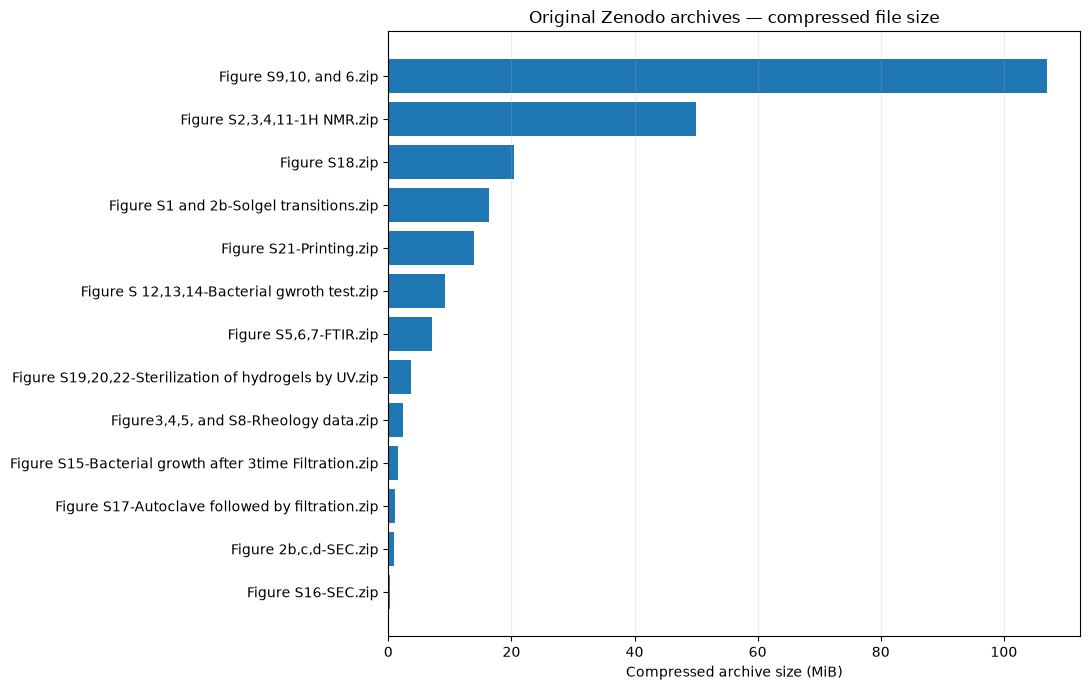

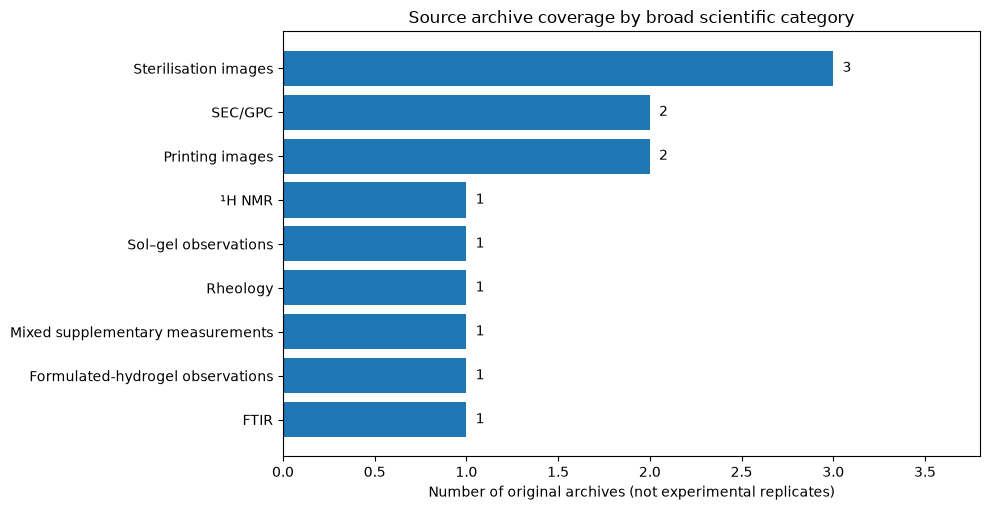

In [20]:
# Matplotlib figures are regenerated with stable filenames every execution.
size_order = archive_df.sort_values('archive_size_mib', ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(size_order['original_filename'], size_order['archive_size_mib'])
ax.set_xlabel('Compressed archive size (MiB)')
ax.set_title('Original Zenodo archives — compressed file size')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'phase0_archive_sizes.png', dpi=170, bbox_inches='tight')
plt.show()

category_counts = archive_df.groupby('broad_category', sort=True).size().sort_values()
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(category_counts.index, category_counts.values)
ax.set_xlabel('Number of original archives (not experimental replicates)')
ax.set_title('Source archive coverage by broad scientific category')
ax.set_xlim(0, max(category_counts.values) + 0.8)
for i, value in enumerate(category_counts.values):
    ax.text(value + 0.05, i, str(int(value)), va='center')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'phase0_scientific_category_coverage.png', dpi=170, bbox_inches='tight')
plt.show()

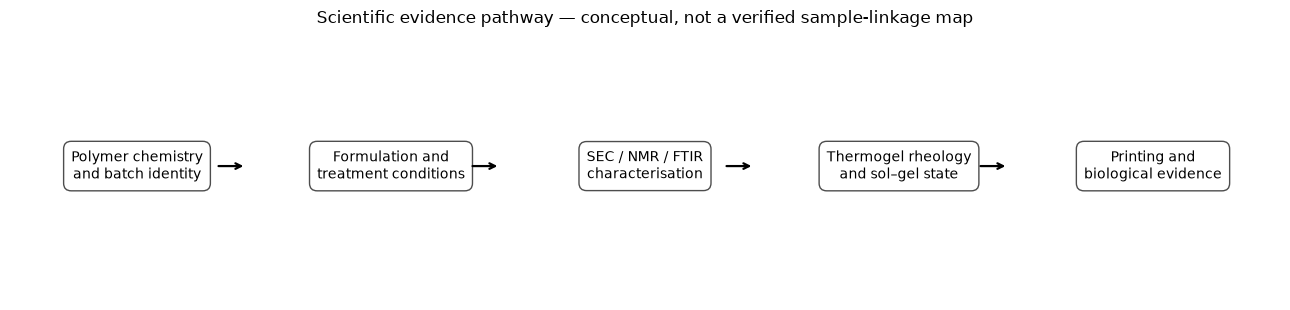

In [21]:
# The boxes below illustrate scientific reasoning, not confirmed experiment-to-sample links.
stages = [
    'Polymer chemistry\nand batch identity',
    'Formulation and\ntreatment conditions',
    'SEC / NMR / FTIR\ncharacterisation',
    'Thermogel rheology\nand sol–gel state',
    'Printing and\nbiological evidence',
]
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.set_xlim(0, 5)
ax.set_ylim(0, 1)
ax.axis('off')
for i, stage in enumerate(stages):
    ax.text(i + 0.5, 0.52, stage.replace('\\n','\n'), ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.55', facecolor='white', edgecolor='0.3'))
    if i < len(stages) - 1:
        ax.annotate('', xy=(i + 0.93, 0.52), xytext=(i + 0.81, 0.52),
                    arrowprops=dict(arrowstyle='->', lw=1.6))
ax.set_title('Scientific evidence pathway — conceptual, not a verified sample-linkage map', pad=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'phase0_scientific_evidence_pathway.png', dpi=170, bbox_inches='tight')
plt.show()

## 10. Provenance, reproducibility and validation

**Scientific integrity:** Original experimental archives remain unchanged. A checksum identifies the *bytes of a source file*, not a material specimen. A `run_manifest.json` records software versions, source checksums and output paths; this supports traceability when the notebook is run again.

**Validation requirements:** Every listed ZIP must pass CRC verification; registered keys must be unique; all expected Phase 0 outputs must exist and contain the required columns. Repeated executions must not create duplicate suffixed filenames.

In [23]:
artifact_files = [
    'source_registry.csv', 'archive_registry.csv', 'polymer_system_register.csv',
    'published_batch_descriptions.csv', 'published_treatment_register.csv',
    'experimental_technique_register.csv', 'research_questions.csv',
    'metadata_requirements.csv', 'preliminary_qc_rules.csv',
    'phase0_input_verification.csv',
]
figure_files = [
    'phase0_archive_sizes.png', 'phase0_scientific_category_coverage.png',
    'phase0_scientific_evidence_pathway.png',
]

# Manifest deliberately excludes wall-clock timestamps to support identical rerun outputs.
manifest = {
    'phase': 'Phase 0 — Scientific Scope and Source Registry',
    'status': 'source_registry_verified; numerical_characterisation_not_performed',
    'source_dataset_doi': DATASET_DOI,
    'experimental_article_doi': ARTICLE_DOI,
    'software_versions': {
        'python': platform.python_version(),
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'matplotlib': matplotlib.__version__,
    },
    'input_archives': [
        {'original_filename': rec['original_filename'], 'sha256': rec['sha256'],
         'archive_size_bytes': int(rec['archive_size_bytes']),
         'internal_file_entries': int(rec['archive_file_entries'])}
        for rec in archive_records
    ],
    'processed_tables': [f'data/processed/phase0/{filename}' for filename in artifact_files],
    'figures': [f'figures/phase0/{filename}' for filename in figure_files],
    'limitations': [
        'File entry counts are not independent experimental replicate counts.',
        'Physical-sample linkage is not verified.',
        'Spectroscopy and rheology instrument measurements are not yet numerically standardised.',
        'Original dataset redistribution rights must be verified before publication.'
    ],
}
manifest_path = PROCESSED_DIR / 'phase0_run_manifest.json'
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

validation_checks = [
    ('original_archives_present', len(archive_df) == 13, '13 original source ZIP files registered'),
    ('source_archive_crc', archive_df['integrity_status'].eq('passed_crc').all(), 'Every original ZIP passed CRC validation'),
    ('archive_keys_unique', archive_df['archive_key'].is_unique, 'Unique registry keys'),
    ('polymer_records', len(polymer_df) == 3 and polymer_df['polymer_key'].is_unique, 'Three polymer systems'),
    ('source_records', len(source_registry) == 2 and source_registry['source_key'].is_unique, 'Article and dataset references'),
    ('required_csv_outputs', all((PROCESSED_DIR / f).is_file() for f in artifact_files), 'All Phase 0 CSV outputs exist'),
    ('figures_exist', all((FIGURE_DIR / f).is_file() and (FIGURE_DIR / f).stat().st_size > 1000 for f in figure_files), 'All Phase 0 figures exist'),
    ('metadata_requirements', not metadata_df.empty and metadata_df['field_name'].is_unique, 'Metadata requirements table is structurally valid'),
    ('research_questions', len(questions_df) >= 10, 'Research questions registered'),
    ('no_sample_id_fabrication', not batch_df['is_physical_sample_id'].any(), 'Registry keys are not represented as physical sample IDs'),
]
validation_df = pd.DataFrame(validation_checks, columns=['check_name','passed','details'])
validation_df.to_csv(PROCESSED_DIR / 'phase0_validation_summary.csv', index=False, encoding='utf-8-sig')
assert validation_df['passed'].all(), 'Phase 0 validation failed; see phase0_validation_summary.csv'
print('All', len(validation_df), 'Phase 0 structural validation checks passed.')
display(validation_df)

All 10 Phase 0 structural validation checks passed.


,check_name,passed,details
0,original_archives_present,True,13 original source ZIP files registered
1,source_archive_crc,True,Every original ZIP passed CRC validation
2,archive_keys_unique,True,Unique registry keys
3,polymer_records,True,Three polymer systems
4,source_records,True,Article and dataset references
5,required_csv_outputs,True,All Phase 0 CSV outputs exist
6,figures_exist,True,All Phase 0 figures exist
7,metadata_requirements,True,Metadata requirements table is structurally valid
8,research_questions,True,Research questions registered
9,no_sample_id_fabrication,True,Registry keys are not represented as physical ...


## 11. HTML scientific scope report

The HTML report combines traceable source counts, a polymer system summary, experimental techniques, priority data-quality checks and the generated figures. It deliberately states that the dataset has not yet been numerically characterised or linked at physical-sample level.

In [25]:
# A standalone HTML report uses links relative to reports/phase0/.
figure_html = '\n'.join(
    f'<figure><img src="../../figures/phase0/{html.escape(name, quote=True)}" '
    f'alt="{html.escape(name, quote=True)}"><figcaption>{html.escape(name)}</figcaption></figure>'
    for name in figure_files
)

report_html = """<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Phase 0 — Thermoresponsive Hydrogel Scientific Scope</title>
<style>body{font-family:Arial,Helvetica,sans-serif;margin:35px auto;max-width:1140px;color:#233140;line-height:1.54;padding:0 22px}h1,h2{color:#173a52}h2{border-bottom:1px solid #d8e2e8;padding-bottom:7px}table{border-collapse:collapse;display:block;overflow-x:auto;width:100%;font-size:13px}td,th{border:1px solid #dbe2e7;padding:8px;vertical-align:top}th{background:#e9f0f5;text-align:left}tr:nth-child(even){background:#f8fafb}img{max-width:100%;height:auto}figure{margin:24px 0}figcaption{color:#586a76;font-size:12px}small{color:#586a76}.note{border-left:3px solid #405b72;padding:10px 14px;background:#f4f7f9}</style></head><body>
<h1>Phase 0 — Scientific Scope and Source Registry</h1>
<p><strong>Independent materials-data curation and Python workflow engineering.</strong></p>
<p>Source article: <a href=""""+ARTICLE_DOI+"""">Biomacromolecules (2026)</a>; experimental source: <a href=""""+DATASET_URL+"""">Zenodo 21902628</a>.</p>
<p class="note">Archive-level registration and integrity testing are complete. Numerical spectroscopy, rheology, image measurements and physical-sample linkage are not yet validated. Archive member counts are not independent specimen counts.</p>
<h2>Source inventory</h2>"""+archive_df[['original_filename','broad_category','archive_size_mib','archive_file_entries','integrity_status']].to_html(index=False,escape=True)+"""
<h2>Polymer systems</h2>"""+polymer_df[['polymer_name','architecture','thermal_behaviour','data_science_relevance']].to_html(index=False,escape=True)+"""
<h2>Published treatment overview</h2>"""+treatment_df[['treatment_name','reported_conditions','stage_note']].to_html(index=False,escape=True)+"""
<h2>Measurement techniques and scientific interpretation</h2>"""+technique_df[['technique','scientific_question','critical_metadata','interpretation_limit']].to_html(index=False,escape=True)+"""
<h2>Selected data-quality principles</h2>"""+qc_df[['qc_rule_key','qc_category','rule_or_review_question','response']].to_html(index=False,escape=True)+"""
<h2>Source-register visualisations</h2>"""+figure_html+"""
<h2>Validation summary</h2>"""+validation_df.to_html(index=False,escape=True)+"""
<h2>Phase 1 handover</h2><p>Detailed internal-file classification, duplicate investigations, format-specific parsers and source metadata extraction remain the next workflow stage. Any proposed cross-technique relation must be supported by source evidence.</p>
<p><small>All source content is attributed to the cited original research. This independently authored report contains no claim of affiliation with the source research group.</small></p></body></html>"""
report_file = REPORT_DIR / 'phase0_scientific_scope_report.html'
report_file.write_text(report_html, encoding='utf-8')
assert report_file.stat().st_size > 10000
print('Scientific scope report:', report_file.relative_to(PROJECT_ROOT))

Scientific scope report: reports\phase0\phase0_scientific_scope_report.html


## 12. Phase 0 findings and Phase 1 handover

**Established in Phase 0:** The original deposited archives have been registered using their original names. Their ZIP integrity, sizes, hashes and archive-level entry counts have been calculated. Three polymer systems, method-specific data requirements, source-reported batch descriptions, preliminary quality rules and research questions have been organised in reproducible tables. Source-category figures and a human-readable HTML report are generated from the same register.

**Not established by Phase 0:** Validated extraction of complete SEC/NMR/FTIR/rheology numeric observations; assignment of original instrument files to distinct physical samples; exact biological-replicate counts; microscopy-derived pore dimensions; causal conclusions about sterilisation chemistry.

**Phase 1 handover:** Investigate individual archive member types, folder hierarchies, cross-archive duplicate content, vendor format constraints, instrument metadata coverage and the first systematically logged QC issues. Source values remain unmodified.

**Key learning points:** Polymer chemistry defines which metadata matter. Data science defines how to store them consistently. Reproducible Python ensures that the same source evidence can be audited again without hidden state or manual spreadsheet edits.